## 1. Imports

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

import warnings
warnings.filterwarnings('ignore')

## 2. Load Data

In [18]:
df = pd.read_csv('../data/ds_salaries.csv')
print(df.shape)
df.head()

(3755, 9)


,work_year,experience_level,employment_type,job_title,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,SE,FT,Principal Data Scientist,85847,ES,100,ES,L
1,2023,MI,CT,ML Engineer,30000,US,100,US,S
2,2023,MI,CT,ML Engineer,25500,US,100,US,S
3,2023,SE,FT,Data Scientist,175000,CA,100,CA,M
4,2023,SE,FT,Data Scientist,120000,CA,100,CA,M


## 3. Select Features & Target

In [19]:
FEATURES = ['job_title', 'experience_level', 'employment_type', 'company_size',
            'company_location', 'work_year', 'remote_ratio']
TARGET = 'salary_in_usd'

data = df[FEATURES + [TARGET]].copy()
print(data.shape)
data.head()

(3755, 8)


,job_title,experience_level,employment_type,company_size,company_location,work_year,remote_ratio,salary_in_usd
0,Principal Data Scientist,SE,FT,L,ES,2023,100,85847
1,ML Engineer,MI,CT,S,US,2023,100,30000
2,ML Engineer,MI,CT,S,US,2023,100,25500
3,Data Scientist,SE,FT,M,CA,2023,100,175000
4,Data Scientist,SE,FT,M,CA,2023,100,120000


## 4. Preprocessing

### 4.1 Drop Duplicates

In [20]:
before = len(data)
data = data.drop_duplicates()
print(f'Removed {before - len(data)} duplicates. Remaining rows: {len(data)}')

Removed 1172 duplicates. Remaining rows: 2583


### 4.2 Filter to Selected Job Titles & Locations

In [21]:
ALLOWED_JOBS = ['Data Scientist', 'ML Engineer', 'Data Engineer',
                'Data Analyst', 'Research Scientist']

ALLOWED_LOCATIONS = ['US', 'GB', 'CA', 'DE', 'IN', 'FR', 'AU']

data = data[data['job_title'].isin(ALLOWED_JOBS)]
data['company_location'] = data['company_location'].apply(
    lambda x: x if x in ALLOWED_LOCATIONS else 'Other'
)
print(data.shape)
data['job_title'].value_counts()

(1631, 8)


job_title
Data Engineer         598
Data Scientist        538
Data Analyst          396
Research Scientist     65
ML Engineer            34
Name: count, dtype: int64

### 4.3 Check Missing Values

In [22]:
data.isnull().sum()

job_title           0
experience_level    0
employment_type     0
company_size        0
company_location    0
work_year           0
remote_ratio        0
salary_in_usd       0
dtype: int64

### 4.4 Define Categorical & Numeric Columns

In [23]:
CAT_COLS = ['job_title', 'experience_level', 'employment_type',
            'company_size', 'company_location']
NUM_COLS = ['work_year', 'remote_ratio']

### 4.5 Train / Test Split

In [24]:
X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')

Train: (1304, 7), Test: (327, 7)


### 4.6 Preprocessor (OneHotEncoder + StandardScaler)

In [25]:
preprocessor = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS),
    ('num', StandardScaler(), NUM_COLS)
])

## 5. Evaluation Helper

In [26]:
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    preds = model.predict(X_te)
    mae  = mean_absolute_error(y_te, preds)
    rmse = np.sqrt(mean_squared_error(y_te, preds))
    r2   = r2_score(y_te, preds)
    print(f'{name:40s}  MAE={mae:>10,.0f}  RMSE={rmse:>10,.0f}  R²={r2:.4f}')
    return {'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2, 'pipeline': model}

results = []

## 6. Model Training

### 6.1 Linear Regression

In [27]:
pipe_lr = Pipeline([('pre', preprocessor), ('model', LinearRegression())])
results.append(evaluate('Linear Regression', pipe_lr, X_train, y_train, X_test, y_test))

Linear Regression                         MAE=    36,535  RMSE=    47,844  R²=0.3961


### 6.2 Polynomial Regression (degree=2)

In [28]:
pipe_poly = Pipeline([
    ('pre', preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('model', LinearRegression())
])
results.append(evaluate('Polynomial Regression (d=2)', pipe_poly, X_train, y_train, X_test, y_test))

Polynomial Regression (d=2)               MAE=    39,071  RMSE=    53,293  R²=0.2507


### 6.3 Ridge Regression

In [29]:
pipe_ridge = Pipeline([('pre', preprocessor), ('model', Ridge(alpha=10.0))])
results.append(evaluate('Ridge Regression', pipe_ridge, X_train, y_train, X_test, y_test))

Ridge Regression                          MAE=    36,388  RMSE=    47,627  R²=0.4016


### 6.4 Lasso Regression

In [30]:
pipe_lasso = Pipeline([('pre', preprocessor), ('model', Lasso(alpha=100.0, max_iter=10000))])
results.append(evaluate('Lasso Regression', pipe_lasso, X_train, y_train, X_test, y_test))

Lasso Regression                          MAE=    36,425  RMSE=    47,723  R²=0.3992


### 6.5 Support Vector Regression

In [31]:
pipe_svr = Pipeline([('pre', preprocessor), ('model', SVR(kernel='rbf', C=100000, epsilon=5000))])
results.append(evaluate('SVR (RBF)', pipe_svr, X_train, y_train, X_test, y_test))

SVR (RBF)                                 MAE=    36,827  RMSE=    49,348  R²=0.3576


### 6.6 Decision Tree Regression

In [32]:
pipe_dt = Pipeline([('pre', preprocessor), ('model', DecisionTreeRegressor(max_depth=6, random_state=42))])
results.append(evaluate('Decision Tree', pipe_dt, X_train, y_train, X_test, y_test))

Decision Tree                             MAE=    37,413  RMSE=    50,475  R²=0.3279


### 6.7 Random Forest Regression

In [33]:
pipe_rf = Pipeline([('pre', preprocessor), ('model', RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1))])
results.append(evaluate('Random Forest', pipe_rf, X_train, y_train, X_test, y_test))

Random Forest                             MAE=    37,978  RMSE=    50,510  R²=0.3269


## 7. Model Comparison

In [34]:
df_res = pd.DataFrame([{k: v for k, v in r.items() if k != 'pipeline'} for r in results])
df_res = df_res.sort_values('R2', ascending=False).reset_index(drop=True)
df_res

,Model,MAE,RMSE,R2
0,Ridge Regression,36388.426441,47626.611082,0.401592
1,Lasso Regression,36425.468992,47722.853396,0.399172
2,Linear Regression,36535.100693,47844.439931,0.396106
3,SVR (RBF),36826.913722,49347.589120,0.357564
4,Decision Tree,37412.589235,50474.800452,0.327880
5,Random Forest,37978.165165,50510.258849,0.326935
6,Polynomial Regression (d=2),39071.240907,53293.167812,0.250726


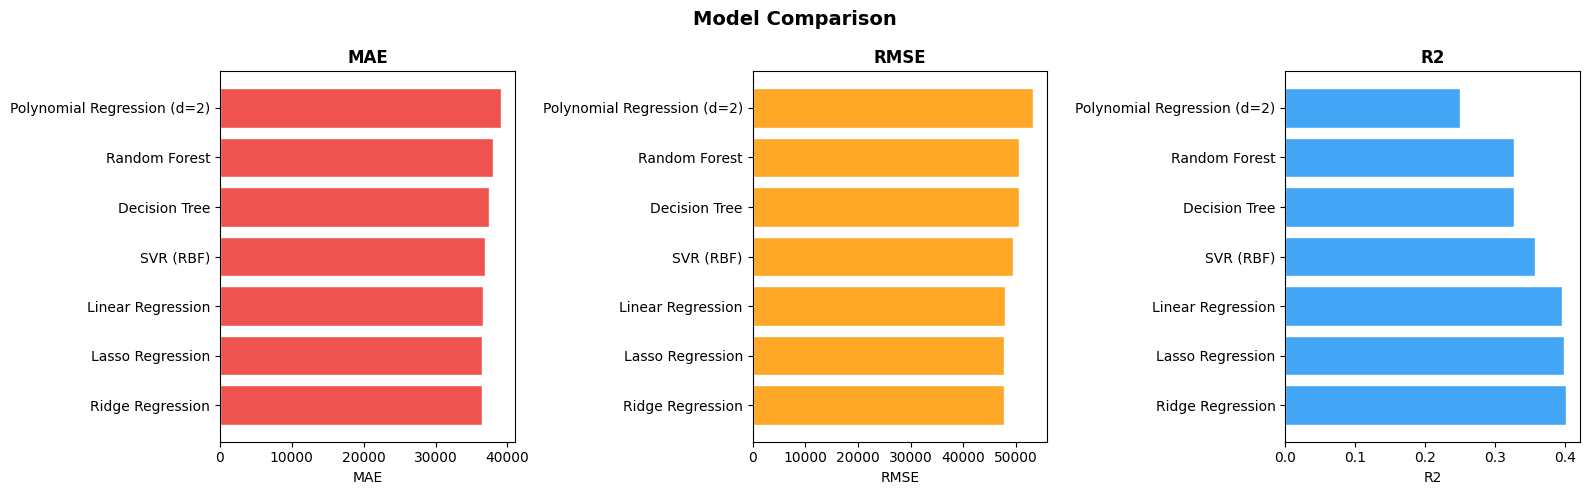

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metrics = ['MAE', 'RMSE', 'R2']
colors  = ['#EF5350', '#FFA726', '#42A5F5']

for ax, metric, color in zip(axes, metrics, colors):
    ascending = metric != 'R2'
    plot_df = df_res.sort_values(metric, ascending=ascending)
    ax.barh(plot_df['Model'], plot_df[metric], color=color, edgecolor='white')
    ax.set_title(metric, fontweight='bold')
    ax.set_xlabel(metric)

plt.suptitle('Model Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Best Model & Saving

In [36]:
best_name = df_res.iloc[0]['Model']
best_pipe = next(r['pipeline'] for r in results if r['Model'] == best_name)
print(f'Best model: {best_name}')

joblib.dump(best_pipe, 'best_model.pkl')
print('Saved to best_model.pkl')

Best model: Ridge Regression
Saved to best_model.pkl


## 9. FastAPI Deployment Guide

Create a file called `app.py` alongside `best_model.pkl`:

```python
from fastapi import FastAPI
from pydantic import BaseModel
import joblib
import pandas as pd

app = FastAPI()
model = joblib.load('best_model.pkl')

class SalaryInput(BaseModel):
    job_title: str
    experience_level: str
    employment_type: str
    company_size: str
    company_location: str
    work_year: int
    remote_ratio: int

@app.post('/predict')
def predict(data: SalaryInput):
    df = pd.DataFrame([data.dict()])
    pred = model.predict(df)[0]
    return {'predicted_salary_usd': round(float(pred), 2)}
```

Then run with:
```bash
pip install fastapi uvicorn joblib
uvicorn app:app --reload
```

Test at: http://127.0.0.1:8000/docs